# MNIST-Fashion
https://github.com/zalandoresearch/fashion-mnist/tree/master

In [ ]:
import numpy as np
from torchvision.datasets import FashionMNIST
train = FashionMNIST(root="data", train=True, download=True)
test = FashionMNIST(root="data", train=False, download=True)
#np.savez("fashion_mnist.npz",
#         x_train=train.data.numpy(), y_train=train.targets.numpy(),
#         x_test=test.data.numpy(), y_test=test.targets.numpy())


In [2]:
print(train.data.numpy().shape)
print(train.targets.numpy().shape)
print(test.data.numpy().shape)
print(test.targets.numpy().shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


## Data visualization
(LLM-assisted: the cells below were written with help from Claude Code, 2026-11-18.)

1. Example images per class
2. Class balance in the training and test sets
3. Mean image and standard deviation per class
4. Distribution of pixel intensities
5. PCA projection (2D) – shows which classes overlap

In [ ]:
# LLM-assisted (Claude Code, 2026-11-18): setup for visualization
import matplotlib.pyplot as plt

x_train, y_train = train.data.numpy(), train.targets.numpy()
x_test, y_test = test.data.numpy(), test.targets.numpy()


class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
n_classes = len(class_names)
SEED = 2026  # each cell that samples creates its own generator, so results do not depend on execution order

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY = "#b4b2a9"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "figure.dpi": 110})

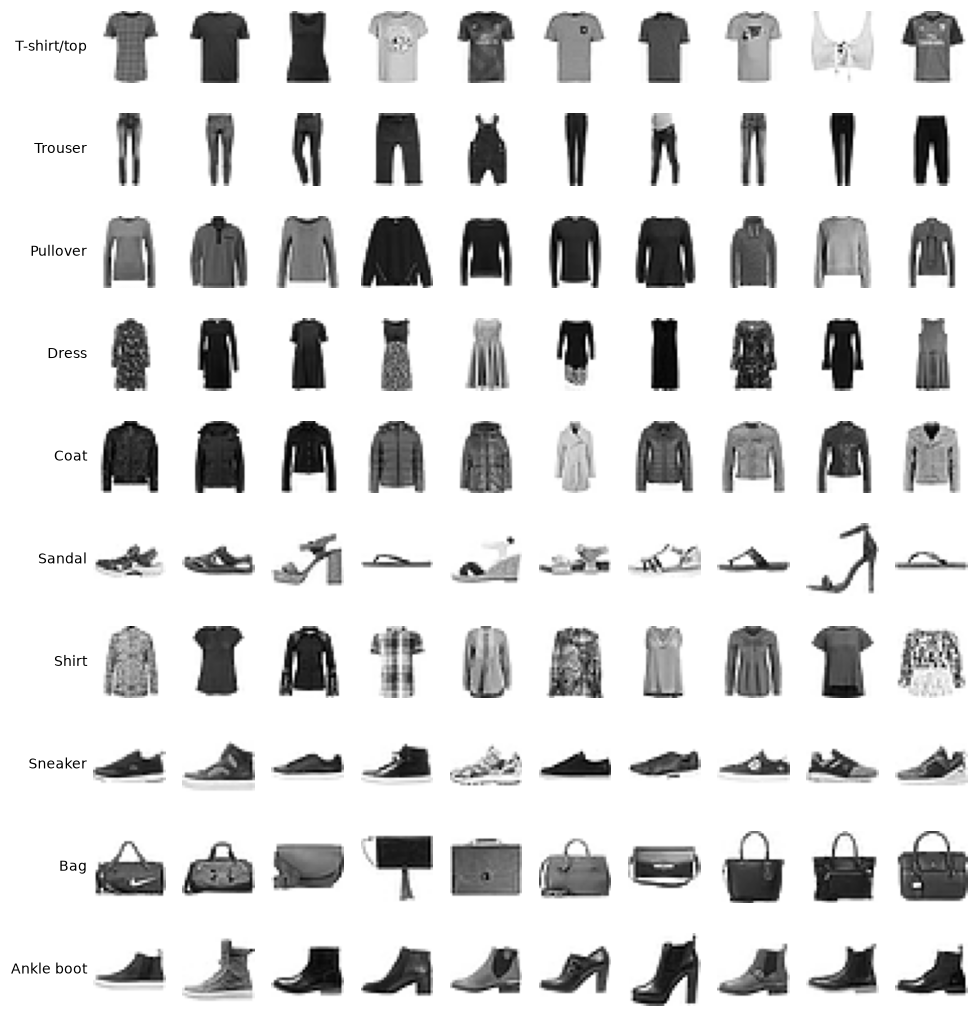

In [10]:
# LLM-assisted (Claude Code, 2026-11-18): grid with 10 random examples per class
rng = np.random.default_rng(SEED)
n_per_class = 10
fig, axes = plt.subplots(n_classes, n_per_class, figsize=(n_per_class * 0.9, n_classes * 0.95))
for c in range(n_classes):
    idx = rng.choice(np.flatnonzero(y_train == c), n_per_class, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(x_train[i], cmap="gray_r", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
    axes[c, 0].set_ylabel(class_names[c], rotation=0, ha="right", va="center", fontsize=9)
#fig.suptitle("Fashion-MNIST: Random examples from the training set", y=1.0)
plt.tight_layout()
plt.show()

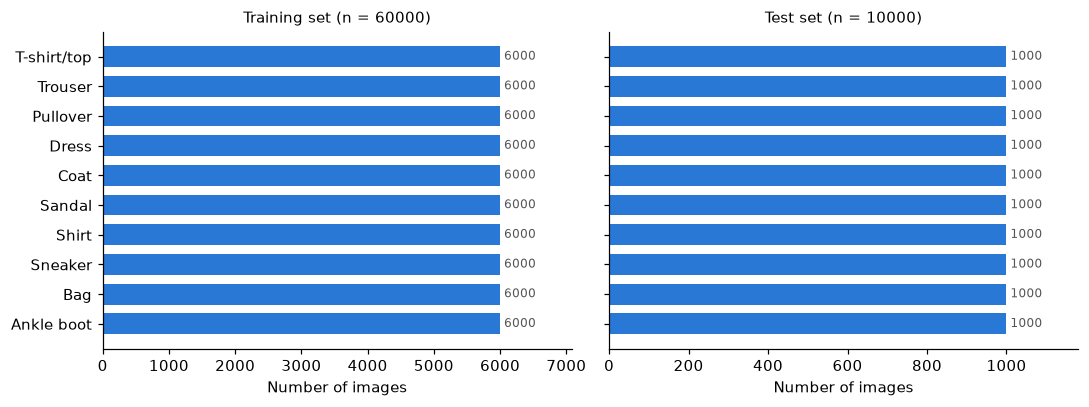

Fraction per class (train): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Fraction per class (test):  [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [5]:
# LLM-assisted (Claude Code, 2026-11-18): class balance (two panels, since the sets differ in size)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, y, name in zip(axes, [y_train, y_test], ["Training set", "Test set"]):
    counts = np.bincount(y, minlength=n_classes)
    ax.barh(range(n_classes), counts, color=BLUE, height=0.7)
    for k, v in enumerate(counts):
        ax.text(v, k, f" {v}", va="center", fontsize=8, color="#555")
    ax.set_title(f"{name} (n = {len(y)})", fontsize=10)
    ax.set_xlabel("Number of images")
    ax.set_xlim(0, counts.max() * 1.18)
axes[0].set_yticks(range(n_classes), class_names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

print("Fraction per class (train):", np.round(np.bincount(y_train) / len(y_train), 3))
print("Fraction per class (test): ", np.round(np.bincount(y_test) / len(y_test), 3))

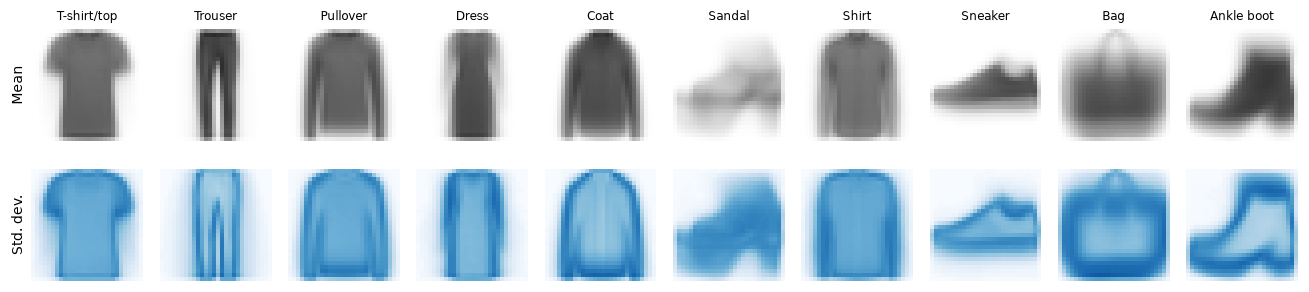

In [6]:
# LLM-assisted (Claude Code, 2026-11-18): mean image (top) and standard deviation (bottom) per class
X = x_train.astype(np.float32) / 255.0
fig, axes = plt.subplots(2, n_classes, figsize=(n_classes * 1.2, 3.0))
for c in range(n_classes):
    Xc = X[y_train == c]
    axes[0, c].imshow(Xc.mean(axis=0), cmap="gray_r", vmin=0, vmax=1)
    axes[1, c].imshow(Xc.std(axis=0), cmap="Blues", vmin=0, vmax=0.5)
    axes[0, c].set_title(class_names[c], fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
axes[0, 0].set_ylabel("Mean", fontsize=9)
axes[1, 0].set_ylabel("Std. dev.", fontsize=9)
plt.tight_layout()
plt.show()

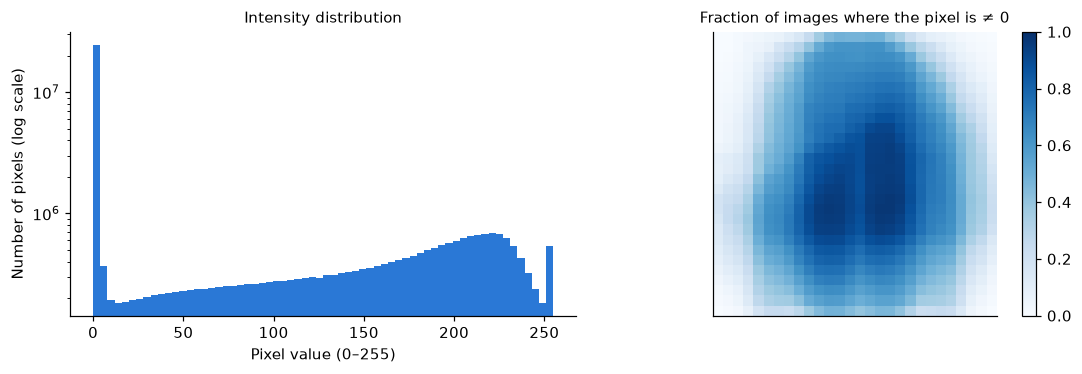

Fraction of pixels equal to 0: 0.502
Pixels that are 0 in every training image: 0 of 784


In [7]:
# LLM-assisted (Claude Code, 2026-11-18): distribution of pixel intensities (all training images)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(x_train.ravel(), bins=64, color=BLUE, log=True)
axes[0].set_xlabel("Pixel value (0–255)")
axes[0].set_ylabel("Number of pixels (log scale)")
axes[0].set_title("Intensity distribution", fontsize=10)

frac_nonzero = (x_train > 0).mean(axis=0)  # fraction of images where the pixel is > 0
im = axes[1].imshow(frac_nonzero, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Fraction of images where the pixel is ≠ 0", fontsize=10)
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

print(f"Fraction of pixels equal to 0: {(x_train == 0).mean():.3f}")
print(f"Pixels that are 0 in every training image: {(frac_nonzero == 0).sum()} of 784")

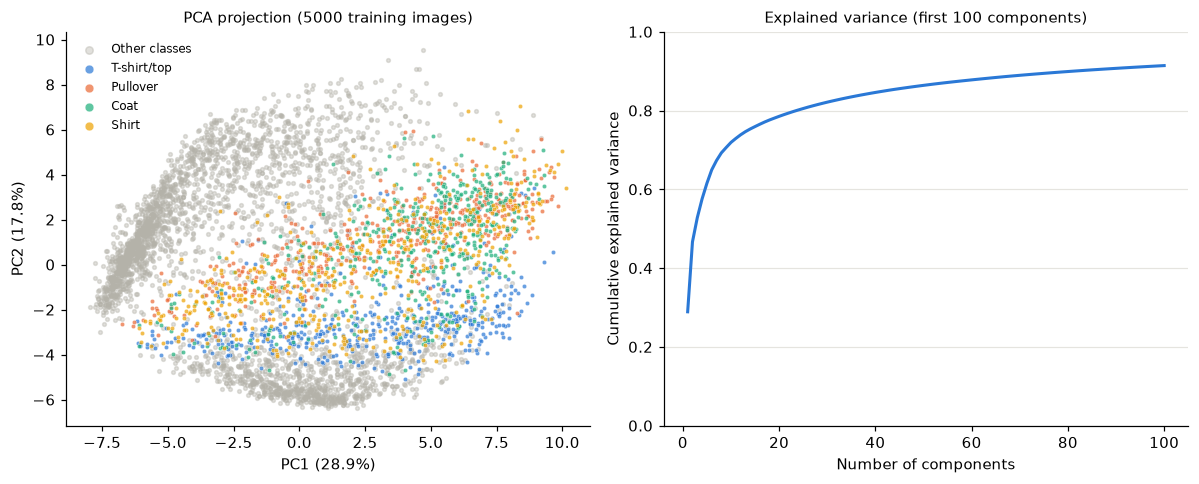

10 components: 71.9%, 100 components: 91.4% of the variance


In [9]:
# LLM-assisted (Claude Code, 2026-11-18): 2D PCA projection of 5000 training images.
# The upper-body garments (often confused) are colored, the remaining classes are gray.
from sklearn.decomposition import PCA

rng = np.random.default_rng(SEED)
sub = rng.choice(len(x_train), 5000, replace=False)
X_sub = x_train[sub].reshape(len(sub), -1) / 255.0
y_sub = y_train[sub]

pca = PCA(n_components=100, random_state=SEED).fit(X_sub)
Z = pca.transform(X_sub)

highlight = {0: BLUE, 2: ORANGE, 4: AQUA, 6: YELLOW}  # T-shirt/top, Pullover, Coat, Shirt
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
other = ~np.isin(y_sub, list(highlight))
ax.scatter(Z[other, 0], Z[other, 1], s=6, color=GRAY, alpha=0.4, label="Other classes")
for c, col in highlight.items():
    m = y_sub == c
    ax.scatter(Z[m, 0], Z[m, 1], s=8, color=col, alpha=0.7, edgecolors="white",
               linewidths=0.3, label=class_names[c])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA projection (5000 training images)", fontsize=10)
ax.legend(fontsize=8, markerscale=2, frameon=False)

ax = axes[1]
cum = np.cumsum(pca.explained_variance_ratio_)
ax.plot(np.arange(1, len(cum) + 1), cum, color=BLUE, lw=2)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_ylim(0, 1)
ax.grid(axis="y", color="#e5e4df", lw=0.8)
ax.set_title("Explained variance (first 100 components)", fontsize=10)
plt.tight_layout()
plt.show()

print(f"10 components: {cum[9]:.1%}, 100 components: {cum[99]:.1%} of the variance")

# Choosing a Subset and scaling
This should be done in a separete python file in /Structure

In [ ]:
x_train, y_train = train.data.numpy(), train.targets.numpy()
x_test, y_test = test.data.numpy(), test.targets.numpy()

x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(data["x_test"]), -1) / 255.0
rng = np.random.default_rng(2026)
# Choosing a subset of 1000 data points
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 100, replace=False) for c in range(10)])
# x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
X_sub, y_sub = x_train[sub], y_train[sub]
